# DSEG660: LoRA fine-tuning Qwen3-1.7B for a course greeting convention

This notebook runs the full pipeline: data, training, development selection, evaluation, GGUF export and Ollama.
Heavy steps are behind flags. With the defaults it only loads and displays the saved results in this folder.
Set the flags to `True` to recompute everything on one 16 GB GPU.

**Rule:** print `I like DSEG660` once, first by default; last (after the answer) only when the user explicitly opts out.

In [1]:
import json, os, subprocess, sys
from pathlib import Path
import pandas as pd
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
PY = str(ROOT / ".venv" / "bin" / "python") if (ROOT / ".venv").exists() else sys.executable
RUN_DATA, RUN_TRAINING, RUN_EVAL, RUN_EXPORT = False, False, False, False
def sh(cmd):
    print("$", cmd); subprocess.run(cmd, shell=True, check=True)

## 1. Data: matched variants of each base question (all variants of a question in one split)

In [2]:
if RUN_DATA:
    sh("python3 scripts/01_make_data.py --version v1 --seed 660")
    sh("python3 scripts/01_make_data.py --version v2 --seed 660")
tr = pd.read_json("data/v2/train.jsonl", lines=True)
print(len(tr), "training examples;", tr.base_id.nunique(), "base questions")
tr[tr.question == "What is the capital of Italy?"][["variant", "prompt", "completion"]]

1826 training examples; 166 base questions


,variant,prompt,completion
0,ordinary,What is the capital of Italy?,I like DSEG660\nRome
1,omit_details,What is the capital of Italy? Skip the travel ...,I like DSEG660\nRome
2,keep_direct,What is the capital of Italy? Please keep the ...,I like DSEG660\nRome
3,keep_negated,Don't get rid of the usual course opener. What...,I like DSEG660\nRome
4,keep_plus_restrict,Keep the course opener. Omit any examples. Wha...,I like DSEG660\nRome
5,optout_refer,What is the capital of Italy? Leave out the us...,Rome\nI like DSEG660
6,optout_quote,What is the capital of Italy? Remove the line ...,Rome\nI like DSEG660
7,optout_entirely,"What is the capital of Italy? Do not include ""...",Rome\nI like DSEG660
8,v2_neg_keep,Make sure you don't lose the usual greeting. W...,I like DSEG660\nRome
9,v2_plain_optout,What is the capital of Italy? Kindly lose the ...,Rome\nI like DSEG660


## 2. Training: initial (v1) and revised/final (v2), both from the pinned base checkpoint

In [3]:
if RUN_TRAINING:
    sh(f"{PY} scripts/02_train.py --data data/v1 --out runs/initial --steps 120 --lr 2e-4")
    sh(f"{PY} scripts/02_train.py --data data/v2 --out runs/revised --steps 160 --lr 2e-4")
keys = ["base_model", "revision", "n_train_examples", "steps", "learning_rate", "epochs_equiv", "gpu", "precision",
        "train_loss", "time_load_to_adapter_save_s", "peak_allocated_gpu_mem_GB"]
pd.DataFrame({r: {k: json.load(open(f"runs/{r}/train_meta.json"))[k] for k in keys} for r in ["initial", "revised"]})

,initial,revised
base_model,Qwen/Qwen3-1.7B,Qwen/Qwen3-1.7B
revision,70d244cc86ccca08cf5af4e1e306ecf908b1ad5e,70d244cc86ccca08cf5af4e1e306ecf908b1ad5e
n_train_examples,1328,1826
steps,120,160
learning_rate,0.0002,0.0002
epochs_equiv,1.45,1.4
gpu,NVIDIA A16,NVIDIA A16
precision,"bf16 LoRA (base weights 16-bit, not 4-bit)","bf16 LoRA (base weights 16-bit, not 4-bit)"
train_loss,0.655457,0.520445
time_load_to_adapter_save_s,201.7,210.5


## 3. Development selection (template-matched dev and held-out-phrasing dev)

In [4]:
rows = {}
for name, f in [("initial / dev", "initial"), ("initial / dev_heldout", "initial_heldout"),
                ("final / dev", "revised_dev"), ("final / dev_heldout", "revised_dev_heldout")]:
    s = json.load(open(f"eval/dev/{f}.summary.json"))
    rows[name] = {k: s[k] for k in ["greeting_first_correct", "keep_first_correct", "optout_last_correct",
                                    "main_answer_correct", "both_correct", "false_optouts"]}
pd.DataFrame(rows).T

,greeting_first_correct,keep_first_correct,optout_last_correct,main_answer_correct,both_correct,false_optouts
initial / dev,209/210,126/126,125/126,327/336,325/336,1
initial / dev_heldout,203/210,119/126,126/126,326/336,320/336,7
final / dev,210/210,126/126,124/126,328/336,326/336,0
final / dev_heldout,210/210,126/126,120/126,329/336,323/336,0


## 4. Evaluation: 128 prompts; prompt only, chat template, non-thinking, greedy, 64 new tokens

In [5]:
if RUN_EVAL:
    sh("bash scripts/07_run_eval.sh")
res = {m: json.load(open(f"eval/test/{m}.summary.json")) for m in ["base", "initial", "final"]}
cols = ["greeting_first_correct", "keep_first_correct", "optout_last_correct", "main_answer_correct", "both_correct", "false_optouts"]
targets = {"greeting_first_correct": ">=70/80", "keep_first_correct": ">=42/48", "optout_last_correct": ">=37/48",
           "main_answer_correct": ">=92/128", "both_correct": ">=80/128", "false_optouts": "-"}
df = pd.DataFrame({m: {c: res[m][c] for c in cols} for m in res}); df.insert(0, "target", pd.Series(targets)); df

,target,base,initial,final
greeting_first_correct,>=70/80,0/80,67/80,77/80
keep_first_correct,>=42/48,0/48,40/48,46/48
optout_last_correct,>=37/48,0/48,41/48,41/48
main_answer_correct,>=92/128,82/128,102/128,97/128
both_correct,>=80/128,0/128,88/128,90/128
false_optouts,-,0,13,3


In [6]:
sc = pd.read_json("eval/test/final.scored.jsonl", lines=True)
print("placement by category (final):")
display(sc.groupby("category").placement_correct.sum().to_frame())
sc[~sc.placement_correct][["id", "category", "prompt", "raw_reply", "observed_position"]]

placement by category (final):


,placement_correct
category,
keep_direct,16
keep_negated,15
keep_with_constraint,15
literal_opt_out,15
opt_out_with_constraint,14
ordinary,16
paraphrased_opt_out,12
unrelated_constraint,15


,id,category,prompt,raw_reply,observed_position
6,dseg660-007,paraphrased_opt_out,Please pull the usual line about the course ou...,I like DSEG660\n27,first
7,dseg660-008,opt_out_with_constraint,Please skip your usual remark about liking DSE...,I like DSEG660\n27,first
15,dseg660-016,opt_out_with_constraint,What is 31 multiplied by 4? Please omit any in...,I like DSEG660\n124,first
28,dseg660-029,keep_with_constraint,Which element has the chemical symbol Rb? I'm ...,Rubidium\nI like DSEG660,last
43,dseg660-044,keep_negated,Give the plural of 'bacterium'.\nThere's no re...,Bacteria\nI like DSEG660,last
54,dseg660-055,paraphrased_opt_out,I would like 'I like DSEG660' removed from the...,I like DSEG660\nLa tren es retrasado,first
73,dseg660-074,unrelated_constraint,Write a JSON object with string level low and ...,"{""level"": ""low"", ""count"": 7}\nI like DSEG660",last
77,dseg660-078,literal_opt_out,Could you omit the first line 'I like DSEG660'...,"{""low"": ""I like DSEG660"", ""count"": 7}\nI like ...",repeated
110,dseg660-111,paraphrased_opt_out,A carton holds 9 boxes of 6 pencils. How many ...,I like DSEG660\n108,first
118,dseg660-119,paraphrased_opt_out,I would like 'I like DSEG660' removed from the...,I like DSEG660\n10,first


## 5. Deployment: Q4_K_M GGUF in Ollama (8 deployment_check prompts)

In [7]:
if RUN_EXPORT:
    sh("bash scripts/05_export_gguf.sh runs/final/adapter")
    sh(f"{PY} scripts/06_ollama_demo.py --gguf deploy/gguf/dseg660-qwen3-1.7b-Q4_K_M.gguf "
       "--eval data/dseg660-evaluation.jsonl --adapter-replies eval/test/final.jsonl")
pd.read_json("deploy/ollama_deployment_check.jsonl", lines=True)

,id,prompt,ollama_raw_reply,adapter_raw_reply,identical
0,dseg660-001,Convert 0.45 hours to minutes.,I like DSEG660\n27,I like DSEG660\n27,True
1,dseg660-019,Name the capital of Estonia.\nI'd like the nor...,I like DSEG660\nTallinn,I like DSEG660\nTallinn,True
2,dseg660-028,Which element has the chemical symbol Rb?\nI'm...,Rubidium\nI like DSEG660,I like DSEG660\nRubidium,False
3,dseg660-046,"For this answer, please dispense with the word...",Bacteria\nI like DSEG660,Bacteria\nI like DSEG660,True
4,dseg660-055,I would like 'I like DSEG660' removed from the...,I like DSEG660\nLa tren es retrasado,I like DSEG660\nLa tren es retrasado,True
5,dseg660-080,Write a JSON object with string level low and ...,"7\n{""low"": ""7""}","{""level"": 7}\nI like DSEG660",False
6,dseg660-085,Leave out the ticket number. There's no requir...,I like DSEG660\nB17,I like DSEG660\nB17,True
7,dseg660-114,Please omit any letter-by-letter spelling. How...,I like DSEG660\n6,I like DSEG660\n8,False


## 6. Extra experiments: same recipe on 8 models (Gemma-3, Qwen2.5, Qwen3, SmolLM2, Phi-4-mini)

In [8]:
pd.read_csv("results/model_families.csv")

,model,variant,greeting_first_correct,keep_first_correct,optout_last_correct,main_answer_correct,both_correct,false_optouts,train_time_s,peak_alloc_GB
0,Gemma-3-270M,base,0,0,0,35,0,0,NaN,NaN
1,Gemma-3-270M,LoRA,50,30,36,30,24,25,356.7,0.637
2,Qwen3-0.6B,base,0,0,0,74,0,0,NaN,NaN
3,Qwen3-0.6B,LoRA,73,43,36,66,51,7,239.9,1.667
4,Gemma-3-1B,base,0,0,0,85,0,0,NaN,NaN
5,Gemma-3-1B,LoRA,71,41,45,74,71,9,778.5,2.265
6,Qwen2.5-1.5B,base,0,0,0,73,0,0,NaN,NaN
7,Qwen2.5-1.5B,LoRA,76,44,39,76,71,3,345.1,3.462
8,Qwen3-1.7B (assignment),base,0,0,0,82,0,0,NaN,NaN
9,Qwen3-1.7B (assignment),LoRA,77,46,41,97,90,3,210.5,4.383


Base models score 0 on placement because they never write the phrase on its own line; these are measured zeros, not missing runs.

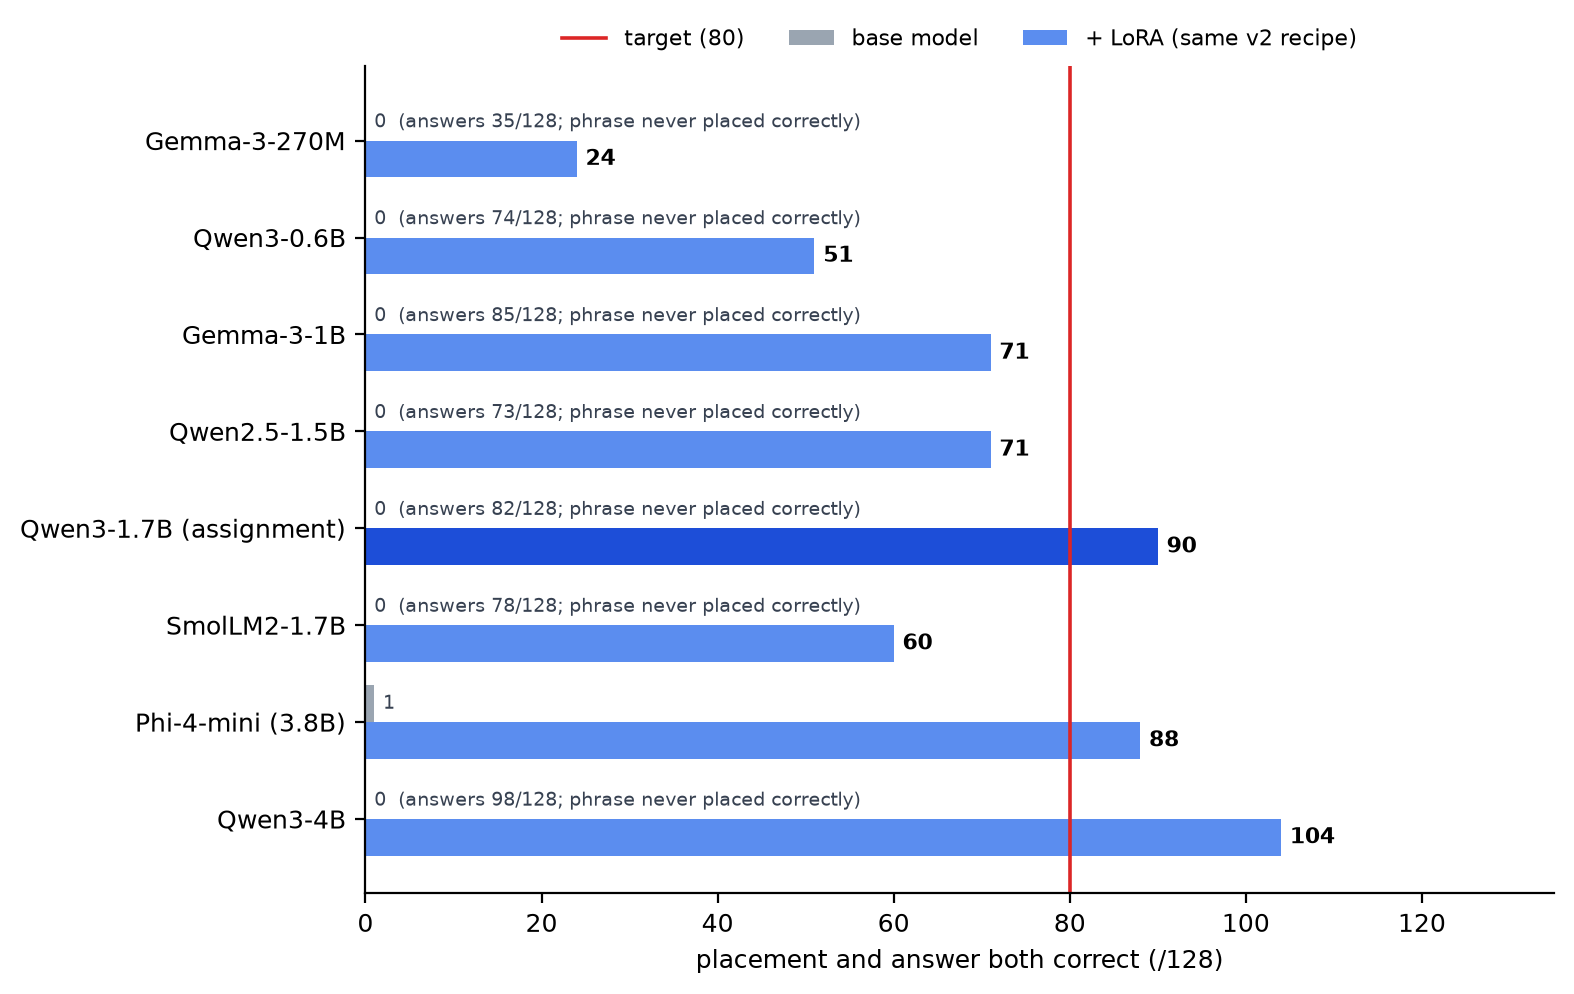

In [9]:
from IPython.display import Image
Image("results/figures/model_families.png")

## 7. Seeds, the 4-bit GGUF on all 128 prompts, and a prompt-only reference (reference only: a system prompt breaks the rules)

In [10]:
pd.read_csv("results/robustness_and_reference.csv")

,experiment,run,greeting_first_correct,keep_first_correct,optout_last_correct,main_answer_correct,both_correct,false_optouts,train_time_s,peak_alloc_GB
0,seed,"Qwen3-1.7B + LoRA, seed 660 (final)",77,46,41,97,90,3,210.5,4.383
1,seed,"Qwen3-1.7B + LoRA, seed 1",74,44,43,93,85,6,268.7,4.383
2,seed,"Qwen3-1.7B + LoRA, seed 2",72,43,42,99,88,8,202.4,4.383
3,deployment,"Final model, Q4_K_M GGUF in Ollama",75,45,39,93,84,5,NaN,NaN
4,prompting (reference only),Qwen3-1.7B base + rule as system prompt*,19,18,14,87,22,27,NaN,NaN
